# The pair test: what the errors leave out

Reported errors are usually treated as independent from channel to channel and frame to frame. Calibration does not work that way: a gain on one baseline, or one telescope, multiplies every channel of a frame at once.

The pair test measures this from the data themselves. Two frames of one target, taken minutes apart in the same configuration, see almost the same uv points, so their **difference is almost pure noise**. Fitting the covariance of many such differences tells us:

* **V²**: independent noise, as a multiple (`white`) of the reported error; a gain per (frame, baseline) (`baseline`); and a gain per (frame, telescope), which enters the three baselines through that telescope (`telescope`). The gains are fractional on V², shared by all channels.
* **Closure phases**: independent noise, again as a multiple of the reported error, with the ±1/3 correlation between triangles that share a baseline; and an offset per (frame, triangle) in degrees (`offset`).

Nested models are fitted by maximum likelihood, so their likelihood gains say which terms the data need.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from virgil.plotting import set_style

from virgil_vlti import read_exposure
from virgil_vlti.pairs import pair_test
from virgil_vlti.synthetic import add_systematics, write_product

set_style()
rng = np.random.default_rng(3)
work = Path(tempfile.mkdtemp())
INS = "GRAVITY_SC"

## Data with a known error structure

Twelve exposures of an unresolved star, 15 minutes apart, each of three frames five minutes apart. `add_systematics` adds the error structure below, of known size: the reported errors are 1% on V² and 1° on closure phase, but the real independent noise is only 60% and 50% of them, and there are correlated gains and offsets on top.

In [2]:
WAVE = np.linspace(2.0e-6, 2.4e-6, 30)
TRUTH = {
    "white": 0.6,  # V² independent noise, × reported error
    "telescope": 0.015,  # gain per (frame, telescope), fractional on V²
    "baseline": 0.01,  # gain per (frame, baseline)
    "cp_white": 0.5,  # closure-phase independent noise, × reported error
    "cp_offset": 0.4,  # offset per (frame, triangle), degrees
}

exposures = []
for k in range(12):
    path = write_product(
        work / f"star{k:02d}.fits",
        mjd=60400.1 + k * 15 / 1440,
        wave=WAVE,
        vis2=lambda u, v, w, t: np.full_like(w, 0.5),
        t3phi=lambda *args: np.zeros_like(args[4]),
        vis2err=0.01,
        t3phierr=1.0,
    )
    add_systematics(path, INS, rng=rng, **TRUTH)
    exposures.append(read_exposure(str(path)))

## Running the test

`pair_test` pairs consecutive frames (no frame is used twice) and fits each nested model. From the command line, `virgil-vlti-pairs calibrated/*.fits --json pairs.json` does the same.

In [3]:
result = pair_test(exposures, INS)
print(result.summary())

18 pairs
V² independent only         ΔlnL      0.0   white 1.221
V² + baseline               ΔlnL   2058.2   white 0.5994  baseline 0.02118
V² + telescope              ΔlnL   1793.1   white 0.6671  telescope 0.01455
V² + baseline + telescope   ΔlnL   2076.7   white 0.5994  baseline 0.009987  telescope 0.01311
CP independent only         ΔlnL      0.0   white 0.6969
CP + triangle offset        ΔlnL    465.7   white 0.4957  offset 0.3991


Each line is one model: ΔlnL is its log-likelihood gain over independent errors alone. Adding the telescope and baseline gains improves V² enormously, and the triangle offsets improve the closure phases: the data need them. The full models recover what we injected:

term                      injected  measured
V² independent (× σ)         0.600     0.599
V² telescope gain            0.015     0.013
V² baseline gain             0.010     0.010
CP independent (× σ)         0.500     0.496
CP triangle offset (°)       0.400     0.399


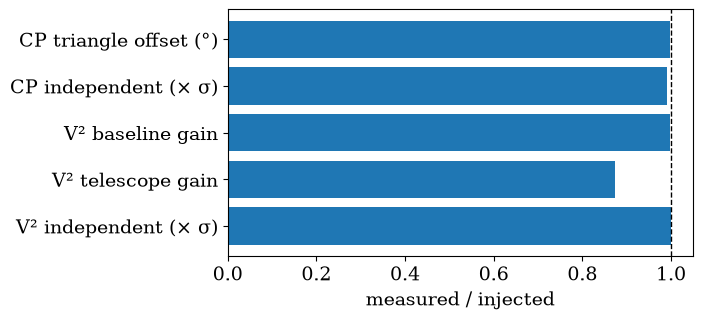

In [4]:
v2 = result.v2["+ baseline + telescope"].widths
cp = result.cp["+ triangle offset"].widths
rows = [
    ("V² independent (× σ)", TRUTH["white"], v2["white"]),
    ("V² telescope gain", TRUTH["telescope"], v2["telescope"]),
    ("V² baseline gain", TRUTH["baseline"], v2["baseline"]),
    ("CP independent (× σ)", TRUTH["cp_white"], cp["white"]),
    ("CP triangle offset (°)", TRUTH["cp_offset"], cp["offset"]),
]
print(f"{'term':<24}{'injected':>10}{'measured':>10}")
for name, true, got in rows:
    print(f"{name:<24}{true:>10.3f}{got:>10.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh([r[0] for r in rows], [r[2] / r[1] for r in rows], color="C0")
ax.axvline(1, color="k", lw=1, ls="--")
ax.set(xlabel="measured / injected")
plt.show()

## Reading the result on real data

* **Independent noise below 1 × σ** means the pipeline's errors overstate the independent part. That isn't safe on its own, because what they leave out is correlated.
* **The gains are lower bounds.** Consecutive exposures usually share calibrators, so calibration errors common to both cancel in the difference. Calibrator-based measures ([templates](templates.md)) catch those.
* **Resolved targets change between frames** as the baselines rotate. Pass `model=` (a function returning the target's predicted V² and closure phases for an exposure) so that its change is subtracted rather than counted as noise.
* **What to do with the widths:** in virgil, gains of these sizes become `OIData.with_gains(telescope=..., baseline=...)` on log |V| (half the fractional V² widths here), with their widths fitted. Offsets become `OIData.with_closure_offsets(triangle=...)` in radians.

On PIONIER data of IW Car, this test found that about a third of the reported V² error is independent, plus gains of about 1% per telescope and per baseline, and closure-phase offsets of 0.2° ([PIONIER](instruments/pionier.md)).